# Fast Synthetic Tracking Algorithm Implementation and a Usage Example
This notebook contains code that implements the class *FastLinRateSynTracking* (Fast Linear Rate Synthetic Tracking)
and the utility function *lrstSearchAndDetect*. They together allow a user to perform fast synthetic tracking (FST). 
*FastLinRateSynTracking* creates an object taking an input of a datacube, which contains image frames to integrate. The object also allocates memory for performing FST; the total memory usage is about twice of the input datacube.

The following code shows the core usage assuming datacube to be a 3D numpy array.
```lrst = FastLinRateSynTracking(datacube)
detectedSignals = []
detection_threshold = 100
Nt = datacube.shape[0] # number of frames
k = np.ones(3,3)/3 # 3x3 kernel
lrst.setVelDir([1,-1]) # vx is positive, vy is negative
integrationInfo = (0, Nt, Nt, 0, 0, 0, 0)
lrstSearchAndDetect(lrst, integrationInfo, detection_threshold, kernel = k, detectedSig = detectedSignals)```

We also provided an example usage of FST, where we created a datacube having six objects at different locations and moving at different rates.

In [ ]:
### This cell provides the core capability of Fast Synthetic Tracking (FST).
import scipy
import numpy as np
class FastLinRateSynTracking:
    """ This class is defined to facilitate integration of frames using linear rate synthetic tracking"""

    # initialization, taking a datacube (frames to integrate) as input
    def __init__(self, dataCube):
        self.Nt = dataCube.shape[0]
        self.Nx = dataCube.shape[1]
        self.Ny = dataCube.shape[2]
        # Nt_ext computes the number of additional intermediate frames needed to ensure sufficient memory allocation when Nt is not a power of 2
        self.Nt_ext = max(2**(np.ceil(np.log2(self.Nt))).astype(int), np.ceil(np.log2(self.Nt)).astype(int) + Nt -1)
          
        self.I_int = np.full((self.Nt_ext + self.Nt, self.Nx, self.Ny), np.nan)
        self.I_int[0:self.Nt] = dataCube
        self.vxDir = 1      # specifying direction of x velocity
        self.vyDir = 1      # specifying direction of x velocity
        self.initFrame = 0  # index of the first frames to be integrated
        self.xOffset = 0    # pixels to shift along x for this level
        self.yOffset = 0    # pixels to shift along y for this level
        self.frameOffset = self.Nt   # an offset for storing frame pair integration results
        self.nFrame = self.Nt        # number of frames to integrate
        # These are used for the case Nt is not a power of 2 to bookkeep the frames left from integrating an odd number of frames
        self.lastFrame = 0  # lastFrame is a flag determining whether there is an unpaired frame left from adding frame pairs.
        self.lastFrameDur = 0  # this works together with the lastFrame, indicating which level this frame was left.

    # set the direction of motion
    def setVelDir(self, xyDir):
        if xyDir[0] < 0 :
          self.vxDir = -1
        else:
          self.vxDir = 1

        if xyDir[1] < 0 :
          self.vyDir = -1
        else:
          self.vyDir = 1
            
    # computing the index for frame shifts and index offsets to facilitate frame shifts     
    def frameShiftIndex(self, dx, dy):
        dx, dy = round(dx), round(dy)
        idx_x_start1, idx_x_end1 = max(-dx, 0), min(self.Nx, self.Nx - dx)
        idx_y_start1, idx_y_end1 = max(-dy, 0), min(self.Ny, self.Ny - dy)
        idx_x_start2, idx_x_end2 = max(dx, 0), min(self.Nx, self.Nx + dx)
        idx_y_start2, idx_y_end2 = max(dy, 0), min(self.Ny, self.Ny + dy)
        return (idx_x_start1, idx_x_end1, idx_y_start1, idx_y_end1, idx_x_start2, idx_x_end2, idx_y_start2, idx_y_end2)

    # core routine to integrate consecutive frame pairs
    def frameIntegration(self, vx_bit, vy_bit):
        if self.allFramesStacked():
            return;
        dx = (self.xOffset + vx_bit)*self.vxDir
        dy = (self.yOffset + vy_bit)*self.vyDir
        nPairs = (self.nFrame - self.lastFrame)//2

        # new unpaired frame, record the step when the single frame occurred
        if self.lastFrame == 0 and self.nFrame % 2:
            self.lastFrameDur = 1
        
        self.I_int[self.frameOffset:(self.frameOffset + nPairs),:,:] = self.I_int[self.initFrame:(self.initFrame+nPairs*2):2,:,:]
        idx_x_start1, idx_x_end1, idx_y_start1, idx_y_end1, idx_x_start2, idx_x_end2, idx_y_start2, idx_y_end2 = self.frameShiftIndex(dx, dy)
        self.I_int[self.frameOffset:(self.frameOffset + nPairs),idx_x_start1:idx_x_end1,idx_y_start1:idx_y_end1] += self.I_int[(self.initFrame+1):(self.initFrame+2*nPairs):2,idx_x_start2:idx_x_end2,idx_y_start2:idx_y_end2]

        self.lastFrame = self.nFrame - 2*nPairs

        # Make sure to integrate the last frame when paired
        if self.lastFrame > 0:
            self.I_int[self.frameOffset + nPairs,:,:] = self.I_int[(self.initFrame+nPairs*2),:,:]
            if self.lastFrame > 1:
                dx = (self.xOffset + vx_bit)*self.vxDir*(1+self.lastFrameDur)/2
                dy = (self.yOffset + vy_bit)*self.vyDir*(1+self.lastFrameDur)/2
                
                idx_x_start1, idx_x_end1, idx_y_start1, idx_y_end1, idx_x_start2, idx_x_end2, idx_y_start2, idx_y_end2 = self.frameShiftIndex(dx, dy)
                self.I_int[self.frameOffset + nPairs,idx_x_start1:idx_x_end1,idx_y_start1:idx_y_end1] += self.I_int[(self.initFrame+self.nFrame-1),idx_x_start2:idx_x_end2,idx_y_start2:idx_y_end2]

                self.lastFrame -= 2
                nPairs += 1

        self.initFrame = self.frameOffset
        self.nFrame = nPairs + self.lastFrame
        self.frameOffset = self.frameOffset + self.nFrame
        self.xOffset = self.xOffset*2 + vx_bit
        self.yOffset = self.yOffset*2 + vy_bit
        self.lastFrameDur *= 0.5

    def sigDetection(self, d_th, kernel = np.ones((1,1)), reset=True):
        if self.nFrame > 1:
            return []
        else:
            detectionLocList = np.nonzero(scipy.signal.convolve2d(self.I_int[self.frameOffset-1,:,:], kernel, mode='same') > d_th) 
            detectedSigList = [(rc[0], rc[1], self.I_int[self.frameOffset-1, rc[0], rc[1]]) for rc in zip(detectionLocList[0], detectionLocList[1])]
            if reset:
                self.resetTracking()
            if len(detectedSigList) > 0 :
                return ((self.xOffset * self.vxDir, self.yOffset * self.vyDir), detectedSigList)
            else:
                return []

    def resetTracking(self):
        self.initFrame = 0
        self.xOffset = 0
        self.yOffset = 0
        self.frameOffset = self.Nt
        self.nFrame = self.Nt
        self.lastFrame = 0
        self.lastFrameDur = 0

    def allFramesStacked(self):
        return self.nFrame == 1

    def setIntInfo(self, integrationInfo):
        self.initFrame = integrationInfo[0]
        self.nFrame = integrationInfo[1]
        self.frameOffset = integrationInfo[2]
        self.lastFrame = integrationInfo[3]
        self.xOffset = integrationInfo[4]
        self.yOffset = integrationInfo[5]
        self.lastFrameDur = integrationInfo[6]

    def getIntInfo(self):
        return (self.initFrame, self.nFrame, self.frameOffset, self.lastFrame, self.xOffset, self.yOffset, self.lastFrameDur)

    def getIntDataFrames(self, fIdx):
        return self.I_int[fIdx,:,:]

# This routine works with FastLinRateSynTracking class, which is the first argument, 
# the second argument is the information at certain level of integration, tuple of (initFrame, frameOffset, lastFrame, xOffset, yOffset, lastFrameDur)
def lrstSearchAndDetect(lrst, integrationInfo, d_th, kernel = np.ones((1,1)), detectedSig = []):
  for x_bit in [0, 1]:
    for y_bit in [0, 1]:
      lrst.setIntInfo(integrationInfo)
      lrst.frameIntegration(x_bit, y_bit)
      
      if lrst.allFramesStacked():
        thisDetection = lrst.sigDetection(d_th, kernel = kernel, reset=False)
        if len(thisDetection) > 0:
          detectedSig.append(thisDetection)
      else:   
        integrationInfoNew = lrst.getIntInfo()
        lrstSearchAndDetect(lrst, integrationInfoNew, d_th, kernel=kernel, detectedSig = detectedSig)

# This routine allows a user to compute an integrated image for a specific motion rate.
def performFST(lrst, rate):
    def int2bin(n, m=8):
        bits = np.zeros((m,))
        bin_str = bin(n)[2:][::-1]
        for ii in range(min(m,len(bin_str))):
            bits[ii] = int(bin_str[ii])
        return bits
    rate_abs = np.array(rate)
    lrst.resetTracking()
    integrationInfo = lrst.getIntInfo()
    dir = [1,1]
    for i in range(2):
        if rate_abs[i] < 0:
            rate_abs[i] = -rate_abs[i]
            dir[i] = -1
    lrst.setVelDir(dir)
    
    m = np.ceil(np.log2(integrationInfo[1])).astype(int)
    n2 = 2**m
    xy_bits = np.zeros((m,2)).astype(int)
    for j in range(2):
        xy_bits[:,j] = int2bin(np.round(rate_abs[j]*(n2-1)).astype(int), m)
        
    for i in range(m):
        lrst.frameIntegration(xy_bits[m-1-i,0], xy_bits[m-1-i,1])

    integrationInfo = lrst.getIntInfo()
    if integrationInfo[1] == 1:
        return lrst.getIntDataFrames(integrationInfo[2]-1)
    else:
        print('Warning: Inconsistency! Frames are not fully integrated!')
        return []

In [2]:
# This cell defines functions to facilitate datacube simulation
import numpy as np

# gaussian profile
def gaussianPsf(x, y, sigma):
    return np.exp(-(x**2 + y**2)*(0.5/sigma**2))

# generate a Guassian Kernel, normalized
def gaussianKernel(sigma, n=7):
    xx = np.tile(np.linspace(0, n-1, n), (n, 1))
    yy = xx. transpose()
    gk = gaussianPsf(xx - (n-1)/2, yy - (n-1)/2, sigma)
    return gk /np.sqrt(np.sum(gk**2))
    
# adding signals of a list of moving objects to the sky background
def addPointSignals(data, pos_list, vel_list, int_list, psf_size, nSub=7):    
    xx = np.tile(np.linspace(0, (nSub-1),nSub), (nSub, 1))
    yy = xx.transpose()
    nObj = len(pos_list)
    centerOffset = round(0.5*(nSub-1))
    Nt = data.shape[0]
        
    for i in range(Nt):
      for j in range(nObj):
        (x0, y0) = pos_list[j]
        (vx, vy) = vel_list[j]
        this_x, this_y = x0 + vx*i, y0 + vy*i
        xI, yI = np.round(this_x).astype(int) - centerOffset, np.round(this_y).astype(int) - centerOffset
        this_psf = gaussianPsf(xx - (this_x - xI), yy - (this_y - yI), psf_size)
        data[i,xI:(xI+nSub)][:, yI:(yI+nSub)] += this_psf*int_list[j]

In [3]:
# Generate a test dataset 
Nx, Ny, Nt = 1000, 1000, 32 # size of the data
np.random.seed(42) 
testData = np.random.normal(0, 1, (Nt, Nx, Ny)) # uniform sky background with noise

# list of objects
pos_list = [(200,300), (700, 80), (250, 700), (500, 600), (100, 800), (800, 700)]
vel_list = [(0.5, 0.8), (-0.25, 0.95), (0.2, -0.75), (-0.85, -0.16), [0.3, -0.4], [-0.7, -0.9]]
I_list = [1.4, 1.8, 1, 1.2, 1.6, 1.5]
psf_size = 1.0

addPointSignals(testData, pos_list, vel_list, I_list, psf_size)

In [4]:
# This cell shows the usage of FST
# detection threshold
det_thr = 7

# search over different directions
vel_dir_list = [(1,1), (1,-1), (-1,1), (-1,-1)]

# instantiate the object that contains the frames to facilitate frame integration
lrst  =  FastLinRateSynTracking(testData)

detectedSig = []
d_th = np.sqrt(Nt)*det_thr # noise level increases after integrating Nt frames.

# adding tracking error 
g_k = gaussianKernel(np.sqrt(np.log2(Nt)/48 + 1/24*(1-1/Nt) + psf_size**2))

for dir in vel_dir_list:
    lrst.setVelDir(dir)
    integrationInfo = (0, Nt, Nt, 0, 0, 0, 0)
    lrstSearchAndDetect(lrst, integrationInfo, d_th, kernel = g_k, detectedSig = detectedSig)

In [5]:
# Extract detected signals from the list
sig_list = []
for (xy, triple_list) in detectedSig:
    x, y = xy
    # triple_list is a list containing one tuple of three numbers
    a, b, c = triple_list[0]
    sig_list.append([x, y, a, b, c])

sig_array = np.array(sig_list)

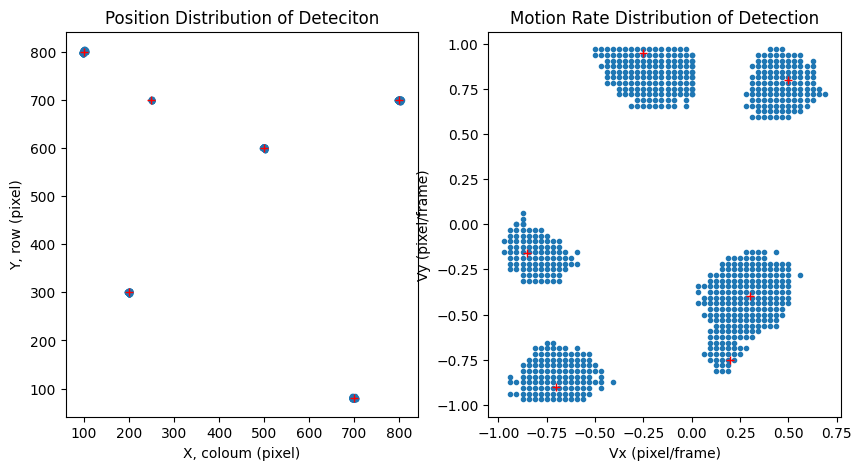

In [6]:
# create plots to show the detections
import matplotlib.pyplot as plt
plt.figure(num=1, figsize=(10, 5))
plt.clf()
plt.subplot(1,2,1)
plt.plot(sig_array[:,2] + sig_array[:,0]*0, sig_array [:, 3] + sig_array[:,1]*0, '.')
plt.plot([pos[0] for pos in pos_list], [pos[1] for pos in pos_list], 'r+')
plt.xlabel('X, coloum (pixel)')
plt.ylabel('Y, row (pixel)')
plt.title('Position Distribution of Deteciton')
plt.subplot(1,2,2)
Nv =2** np.ceil(np.log2(Nt))
plt.plot(sig_array[:,0]/Nv, sig_array [:, 1]/Nv, '.')
plt.plot([v[0] for v in vel_list], [v[1] for v in vel_list], 'r+')
plt.xlabel('Vx (pixel/frame)')
plt.ylabel('Vy (pixel/frame)')
plt.title('Motion Rate Distribution of Detection')
plt.show()